In [1]:
import pandas as pd
import networkx as nx
from node2vec import Node2Vec

# Load dataset
ratings = pd.read_csv("ratings.csv")
movies = pd.read_csv("movies.csv")

# Reduce dataset size (IMPORTANT for speed)
ratings = ratings.head(5000)

# Preprocess genres
movies['genres'] = movies['genres'].str.split('|')

# Graph structure
G = nx.Graph()

# Add User-Movie edges
for _, row in ratings.iterrows():
    user = "user_" + str(row['userId'])
    movie = "movie_" + str(row['movieId'])

    G.add_edge(user, movie)

# Add Movie-Genre edges
sample_movies = ratings['movieId'].unique()
movies_sample = movies[movies['movieId'].isin(sample_movies)]

for _, row in movies_sample.iterrows():
    movie = "movie_" + str(row['movieId'])

    for genre in row['genres']:
        genre_node = "genre_" + genre
        G.add_edge(movie, genre_node)

print("Total nodes:", G.number_of_nodes())
print("Total edges:", G.number_of_edges())

# Node2Vec Embedding
node2vec = Node2Vec(
    G,
    dimensions=64,
    walk_length=20,
    num_walks=100,
    workers=1
)

model = node2vec.fit(
    window=10,
    min_count=1
)

import pickle

with open("node2vec_model.pkl", "wb") as f:
    pickle.dump(model, f)

#To Load and use the model later 
'''
import pickle

with open("node2vec_model.pkl", "rb") as f:
    model = pickle.load(f)

model.wv.most_similar('movie_50')    
'''
# Example embeddings
user_example = [n for n in G.nodes if n.startswith("user_")][0]
print("\nUser embedding:")
print(model.wv[user_example])

# Get a movie that actually exists
movie_example = [n for n in G.nodes if n.startswith("movie_")][0]

print("\nMovie embedding:")
print(model.wv[movie_example])

# Recommendation
print("\nSimilar movies:")
print(model.wv.most_similar(movie_example, topn=5))

# Save embeddings
model.wv.save_word2vec_format("movie_embeddings.txt")

Total nodes: 4906
Total edges: 11295


Computing transition probabilities:   0%|          | 0/4906 [00:00<?, ?it/s]

Generating walks (CPU: 1): 100%|█████████████████████████████████████████████████████| 100/100 [07:33<00:00,  4.54s/it]
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception


User embedding:
[ 0.33546433 -0.20478211  0.25331777 -0.10564261 -0.2299551  -0.38645437
 -0.03835548  0.71966434 -0.32840297 -0.05346623  0.09190613  0.16796313
  0.09357815 -0.47450072 -0.01982659  0.39729962 -0.5916634   0.05455583
  0.03583375  0.07172968  0.2194153  -0.02362927  0.86131364 -0.7077003
  0.20739532  0.33173335  0.09512172  0.07434387  0.315998   -0.1697028
 -0.1260857   0.07825343 -0.07214042 -0.02339909 -0.02402406  0.27574244
  0.48653546  0.5712202   0.20571436 -0.34411883 -0.08755163  0.39103222
  0.28574923 -0.4630155   0.17685364  0.19873847 -0.09834319 -0.79539716
 -0.3263176  -0.2958669   0.10802187  0.21366547 -0.1297769   0.39841998
  0.23411156  0.16531916  0.01697489  0.06944329  0.09142095 -0.19921131
 -0.09124726 -0.74560875 -0.21458293  0.27051988]

Movie embedding:
[ 0.5665852  -0.19057515  0.19057505 -0.02431277  0.36010998 -0.27364078
 -0.2948852   0.08503111 -0.00756067 -0.15334666  0.68379885 -0.16222313
 -0.2771783  -0.1249062   0.2654522   0.0

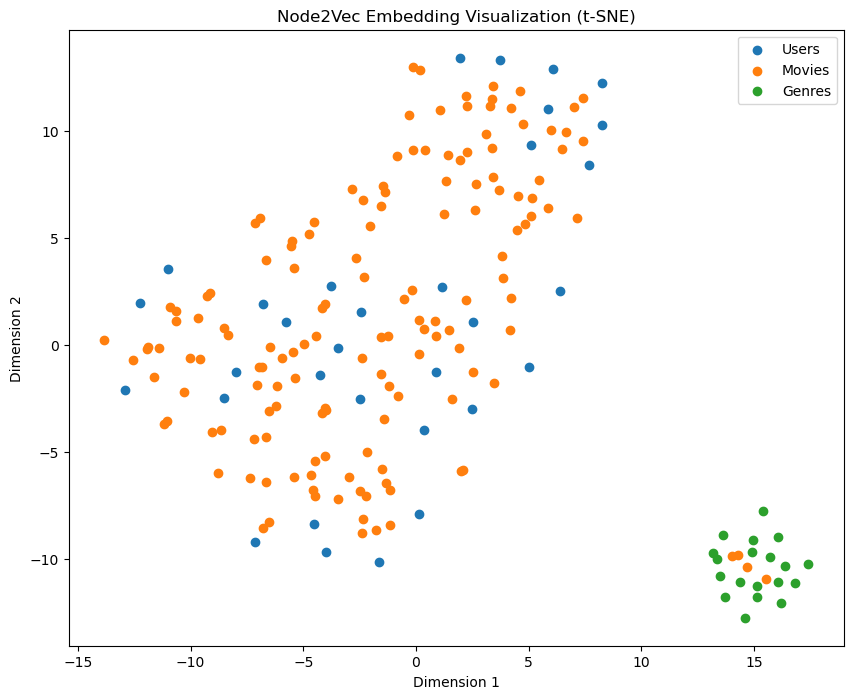

In [2]:
import numpy as np

# Get all node names
nodes = model.wv.index_to_key[:200]

# Get vectors
embeddings = np.array([model.wv[node] for node in nodes])

from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42
)

embeddings_2d = tsne.fit_transform(embeddings)

users_x, users_y = [], []
movies_x, movies_y = [], []
genres_x, genres_y = [], []

for i, node in enumerate(nodes):
    
    if node.startswith("user_"):
        users_x.append(embeddings_2d[i,0])
        users_y.append(embeddings_2d[i,1])
        
    elif node.startswith("movie_"):
        movies_x.append(embeddings_2d[i,0])
        movies_y.append(embeddings_2d[i,1])
        
    elif node.startswith("genre_"):
        genres_x.append(embeddings_2d[i,0])
        genres_y.append(embeddings_2d[i,1])

import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))

plt.scatter(users_x, users_y, label="Users")
plt.scatter(movies_x, movies_y, label="Movies")
plt.scatter(genres_x, genres_y, label="Genres")

plt.legend()
plt.title("Node2Vec Embedding Visualization (t-SNE)")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")

plt.show()        